# Multiclass Classification - Dermatology Dataset

**Objective:** Predict the type of erythemato-squamous disease (6 classes) using patient clinical
and histopathological attributes.

**Target Variable:** `class` (1 = psoriasis, 2 = seboreic dermatitis, 3 = lichen planus,
4 = pityriasis rosea, 5 = cronic dermatitis, 6 = pityriasis rubra pilaris)


In [1]:
# Importing all the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              classification_report, confusion_matrix, roc_curve, auc)

sns.set_style("whitegrid")
%matplotlib inline


## Task 1: Data Acquisition and Exploration

### 1.1 Load the dataset

In [2]:
# The dataset is loaded from a csv file (UCI Dermatology dataset, 366 patients, 34 features + class)
df = pd.read_csv("dermatology.csv")

print("Shape of dataset:", df.shape)
df.head()


Shape of dataset: (366, 35)


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3


In [3]:
# Basic info about the dataset (column names, data types, non-null counts)
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   erythema                                  366 non-null    int64  
 1   scaling                                   366 non-null    int64  
 2   definite_borders                          366 non-null    int64  
 3   itching                                   366 non-null    int64  
 4   koebner_phenomenon                        366 non-null    int64  
 5   polygonal_papules                         366 non-null    int64  
 6   follicular_papules                        366 non-null    int64  
 7   oral_mucosal_involvement                  366 non-null    int64  
 8   knee_and_elbow_involvement                366 non-null    int64  
 9   scalp_involvement                         366 non-null    int64  
 10  family_history                            366 non

### 1.2 Summary statistics

In [4]:
# Summary statistics (mean, std, min, max, quartiles) for all numeric features
df.describe().T


,count,mean,std,min,25%,50%,75%,max
erythema,366.0,2.068306,0.664753,0.0,2.0,2.0,2.00,3.0
scaling,366.0,1.795082,0.701527,0.0,1.0,2.0,2.00,3.0
definite_borders,366.0,1.549180,0.907525,0.0,1.0,2.0,2.00,3.0
itching,366.0,1.366120,1.138299,0.0,0.0,1.0,2.00,3.0
koebner_phenomenon,366.0,0.633880,0.908016,0.0,0.0,0.0,1.00,3.0
polygonal_papules,366.0,0.448087,0.957327,0.0,0.0,0.0,0.00,3.0
follicular_papules,366.0,0.166667,0.570588,0.0,0.0,0.0,0.00,3.0
oral_mucosal_involvement,366.0,0.377049,0.834147,0.0,0.0,0.0,0.00,3.0
knee_and_elbow_involvement,366.0,0.614754,0.982979,0.0,0.0,0.0,1.00,3.0
scalp_involvement,366.0,0.519126,0.905639,0.0,0.0,0.0,1.00,3.0


In [5]:
# Median for every column (describe() above only shows the 50% quartile which is the median,
# printing it separately for clarity as asked in the assignment)
df.median(numeric_only=True)


erythema                                     2.0
scaling                                      2.0
definite_borders                             2.0
itching                                      1.0
koebner_phenomenon                           0.0
polygonal_papules                            0.0
follicular_papules                           0.0
oral_mucosal_involvement                     0.0
knee_and_elbow_involvement                   0.0
scalp_involvement                            0.0
family_history                               0.0
melanin_incontinence                         0.0
eosinophils_in_the_infiltrate                0.0
pnl_infiltrate                               0.0
fibrosis_of_the_papillary_dermis             0.0
exocytosis                                   2.0
acanthosis                                   2.0
hyperkeratosis                               0.0
parakeratosis                                1.0
clubbing_of_the_rete_ridges                  0.0
elongation_of_the_re

### 1.3 Missing values, duplicates and outliers

In [6]:
# Checking for missing values in every column
missing = df.isnull().sum()
print("Columns with missing values:")
print(missing[missing > 0])


Columns with missing values:
age    8
dtype: int64


In [7]:
# Only the "age" column has missing values (8 missing entries).
# Handling missing values by filling them with the median age of the dataset.
df["age"] = df["age"].fillna(df["age"].median())

# confirming no missing values are left
print("Total missing values after imputation:", df.isnull().sum().sum())


Total missing values after imputation: 0


In [8]:
# Checking for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

# Dropping duplicates if any are found
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)


Number of duplicate rows: 0
Shape after removing duplicates: (366, 35)


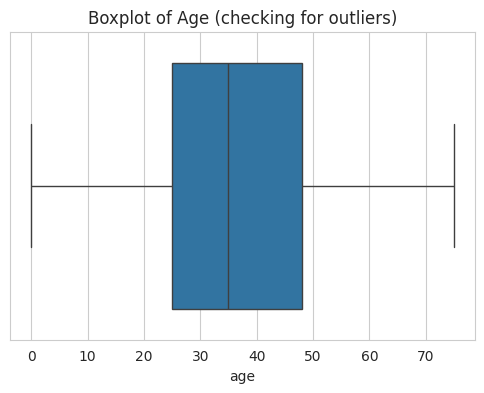

In [9]:
# Checking for outliers using a boxplot on the "age" column
# (the other 34 attributes are ordinal, taking values 0-3, so a boxplot is not very meaningful for them)
plt.figure(figsize=(6,4))
sns.boxplot(x=df["age"])
plt.title("Boxplot of Age (checking for outliers)")
plt.show()


In [10]:
# Using the IQR method to detect outliers in the age column
Q1 = df["age"].quantile(0.25)
Q3 = df["age"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["age"] < lower_bound) | (df["age"] > upper_bound)]
print("Number of outliers in age:", outliers.shape[0])
print("Lower bound:", lower_bound, " Upper bound:", upper_bound)

# Since these outliers are just older/younger patients (a genuine possibility in a medical dataset)
# and there are very few of them, we keep them as they represent valid patient records
# and do not remove them.


Number of outliers in age: 0
Lower bound: -9.5  Upper bound: 82.5


### 1.4 Visualizations

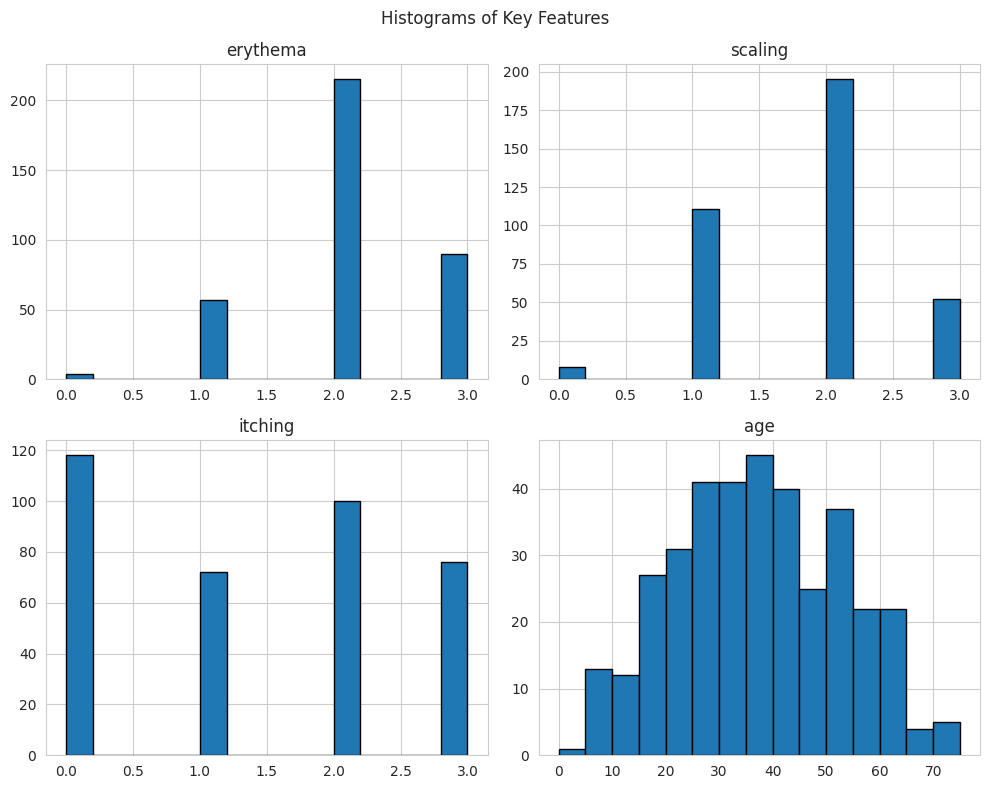

In [11]:
# Histograms of a few key clinical features to see their distributions
key_features = ["erythema", "scaling", "itching", "age"]

df[key_features].hist(figsize=(10, 8), bins=15, edgecolor="black")
plt.suptitle("Histograms of Key Features")
plt.tight_layout()
plt.show()


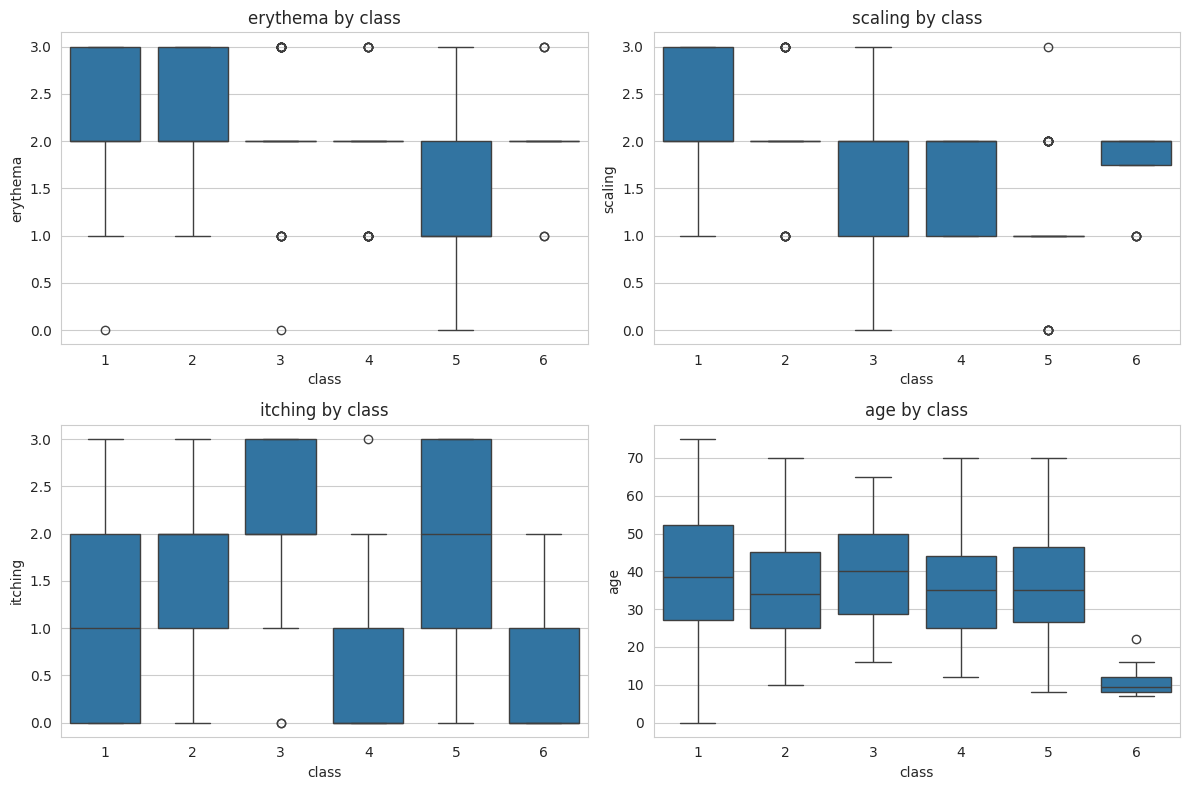

In [12]:
# Boxplots of the same key features grouped by class, to see how they vary across disease classes
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(key_features):
    sns.boxplot(x="class", y=col, data=df, ax=axes[i])
    axes[i].set_title(f"{col} by class")

plt.tight_layout()
plt.show()


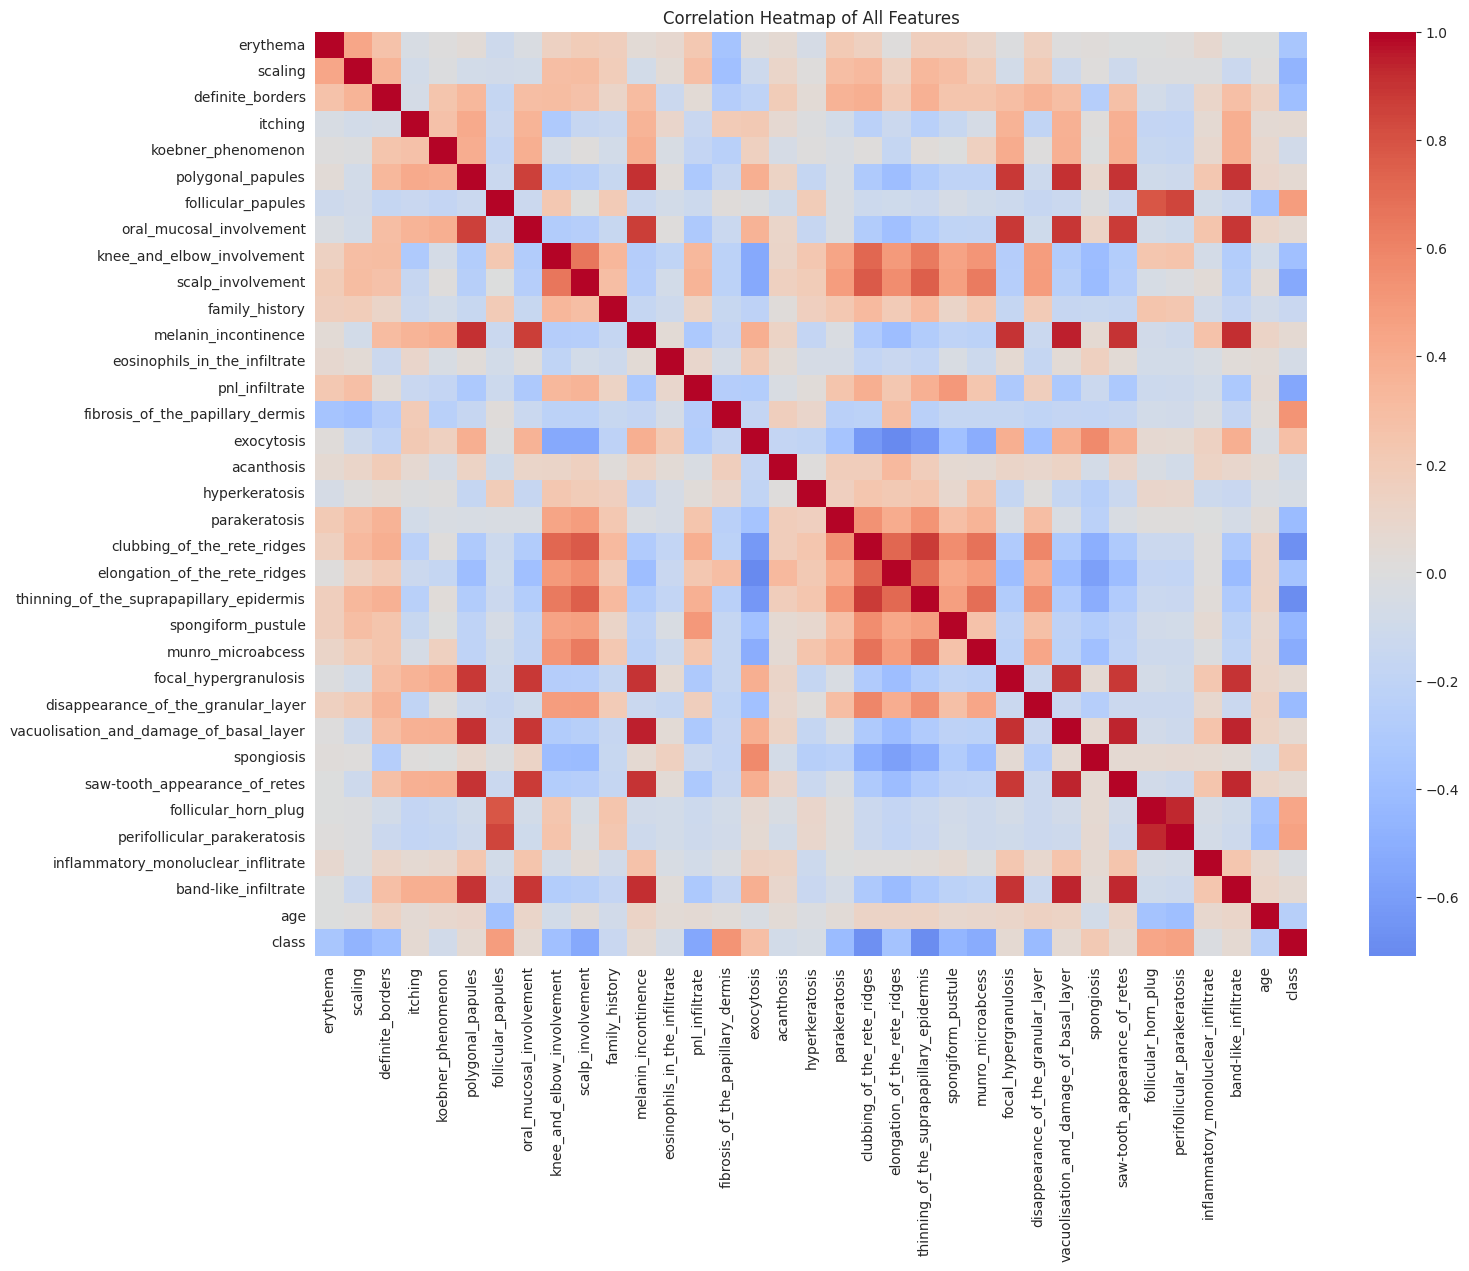

In [13]:
# Correlation heatmap for all features
plt.figure(figsize=(16, 12))
corr = df.corr()
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of All Features")
plt.show()


/tmp/ipykernel_220/2342729349.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="class", data=df, palette="viridis")


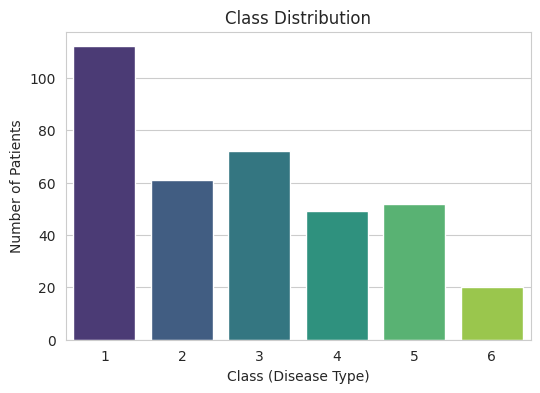

class
1    112
3     72
2     61
5     52
4     49
6     20
Name: count, dtype: int64


In [14]:
# Class distribution plot
plt.figure(figsize=(6, 4))
sns.countplot(x="class", data=df, palette="viridis")
plt.title("Class Distribution")
plt.xlabel("Class (Disease Type)")
plt.ylabel("Number of Patients")
plt.show()

print(df["class"].value_counts())


### 1.5 Discussion on class imbalance

Looking at the class distribution plot and value counts above, the dataset is **imbalanced**:

- Class 1 (psoriasis) has the most patients (112), while Class 6 (pityriasis rubra pilaris) has
  only around 20 patients.
- Classes 2, 4 and 5 also have noticeably fewer samples compared to Class 1 and Class 3.

**Possible implications for model training:**
- The model may become biased towards the majority classes (1 and 3) and perform poorly on the
  minority classes (especially class 6), since it sees fewer examples of them during training.
- Overall accuracy can look high even if the minority classes are misclassified often, so metrics
  like precision, recall and F1-score (per class) are more informative than accuracy alone here.
- Using **stratified sampling** while splitting the data (done in Task 2) helps make sure that the
  train and test sets both have a similar proportion of each class.


## Task 2: Data Preprocessing

### 2.1 Encode the target variable

In [15]:
# Encoding the target variable "class" using LabelEncoder
le = LabelEncoder()
df["class_encoded"] = le.fit_transform(df["class"])

# Mapping of original class labels to encoded labels
print("Classes:", le.classes_)
print("Encoded as:", le.transform(le.classes_))

X = df.drop(columns=["class", "class_encoded"])
y = df["class_encoded"]


Classes: [1 2 3 4 5 6]
Encoded as: [0 1 2 3 4 5]


### 2.2 Train-test split (stratified, 80/20)

In [16]:
# Splitting the data into training and testing sets using stratified sampling
# so that the class proportions are maintained in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nClass proportion in train set:")
print(y_train.value_counts(normalize=True).sort_index())
print("\nClass proportion in test set:")
print(y_test.value_counts(normalize=True).sort_index())


Training set shape: (292, 34)
Testing set shape: (74, 34)

Class proportion in train set:
class_encoded
0    0.304795
1    0.167808
2    0.195205
3    0.133562
4    0.143836
5    0.054795
Name: proportion, dtype: float64

Class proportion in test set:
class_encoded
0    0.310811
1    0.162162
2    0.202703
3    0.135135
4    0.135135
5    0.054054
Name: proportion, dtype: float64


### 2.3 Feature scaling (Standardization)

In [17]:
# Standardizing the features so that all of them are on the same scale (mean=0, std=1)
# This is important for algorithms like KNN, SVM and Logistic Regression which are sensitive
# to the scale of input features.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Mean of scaled training data (should be close to 0):", np.round(X_train_scaled.mean(), 4))
print("Std of scaled training data (should be close to 1):", np.round(X_train_scaled.std(), 4))


Mean of scaled training data (should be close to 0): 0.0
Std of scaled training data (should be close to 1): 1.0


## Task 3: Model Training and Basic Evaluation

We train and compare 5 different multiclass classification algorithms:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Decision Tree
4. Random Forest
5. Support Vector Machine (SVM)


In [18]:
# Defining the models to be trained
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42)
}


In [19]:
# Training each model and storing predictions for evaluation
trained_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    trained_models[name] = model
    predictions[name] = y_pred
    print(f"{name} trained.")


Logistic Regression trained.
KNN trained.
Decision Tree trained.
Random Forest trained.


SVM trained.


### 3.1 Accuracy, Precision, Recall and F1-score

In [20]:
# Computing accuracy, precision, recall and f1-score (weighted average, since we have
# an imbalanced multiclass problem) for every model
results = []

for name, y_pred in predictions.items():
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
    results.append([name, acc, prec, rec, f1])

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1-score"])
results_df = results_df.sort_values(by="Accuracy", ascending=False).reset_index(drop=True)
results_df


,Model,Accuracy,Precision,Recall,F1-score
0,SVM,0.972973,0.977477,0.972973,0.972973
1,Logistic Regression,0.959459,0.968815,0.959459,0.960642
2,Decision Tree,0.959459,0.964619,0.959459,0.959392
3,Random Forest,0.959459,0.960688,0.959459,0.959543
4,KNN,0.905405,0.919305,0.905405,0.908094


/tmp/ipykernel_220/925246027.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Model", y="Accuracy", data=results_df, palette="mako")


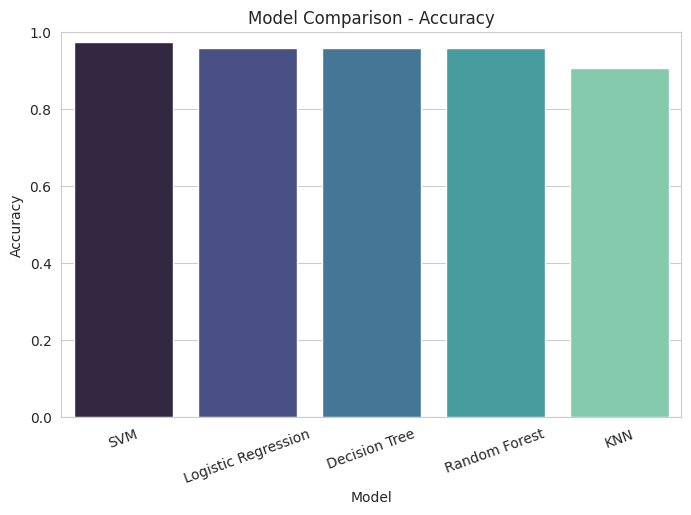

In [21]:
# Bar plot comparing accuracy of all models
plt.figure(figsize=(8, 5))
sns.barplot(x="Model", y="Accuracy", data=results_df, palette="mako")
plt.title("Model Comparison - Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()


In [22]:
# Detailed classification report (precision, recall, f1-score per class) for each model
for name, y_pred in predictions.items():
    print(f"----- Classification Report: {name} -----")
    print(classification_report(y_test, y_pred, target_names=[str(c) for c in le.classes_], zero_division=0))


----- Classification Report: Logistic Regression -----
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.83      0.91        12
           3       1.00      0.93      0.97        15
           4       0.77      1.00      0.87        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.96      0.96      0.96        74
weighted avg       0.97      0.96      0.96        74

----- Classification Report: KNN -----
              precision    recall  f1-score   support

           1       1.00      0.96      0.98        23
           2       0.80      0.67      0.73        12
           3       1.00      0.93      0.97        15
           4       0.64      0.90      0.75        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00     

### 3.2 Confusion matrices

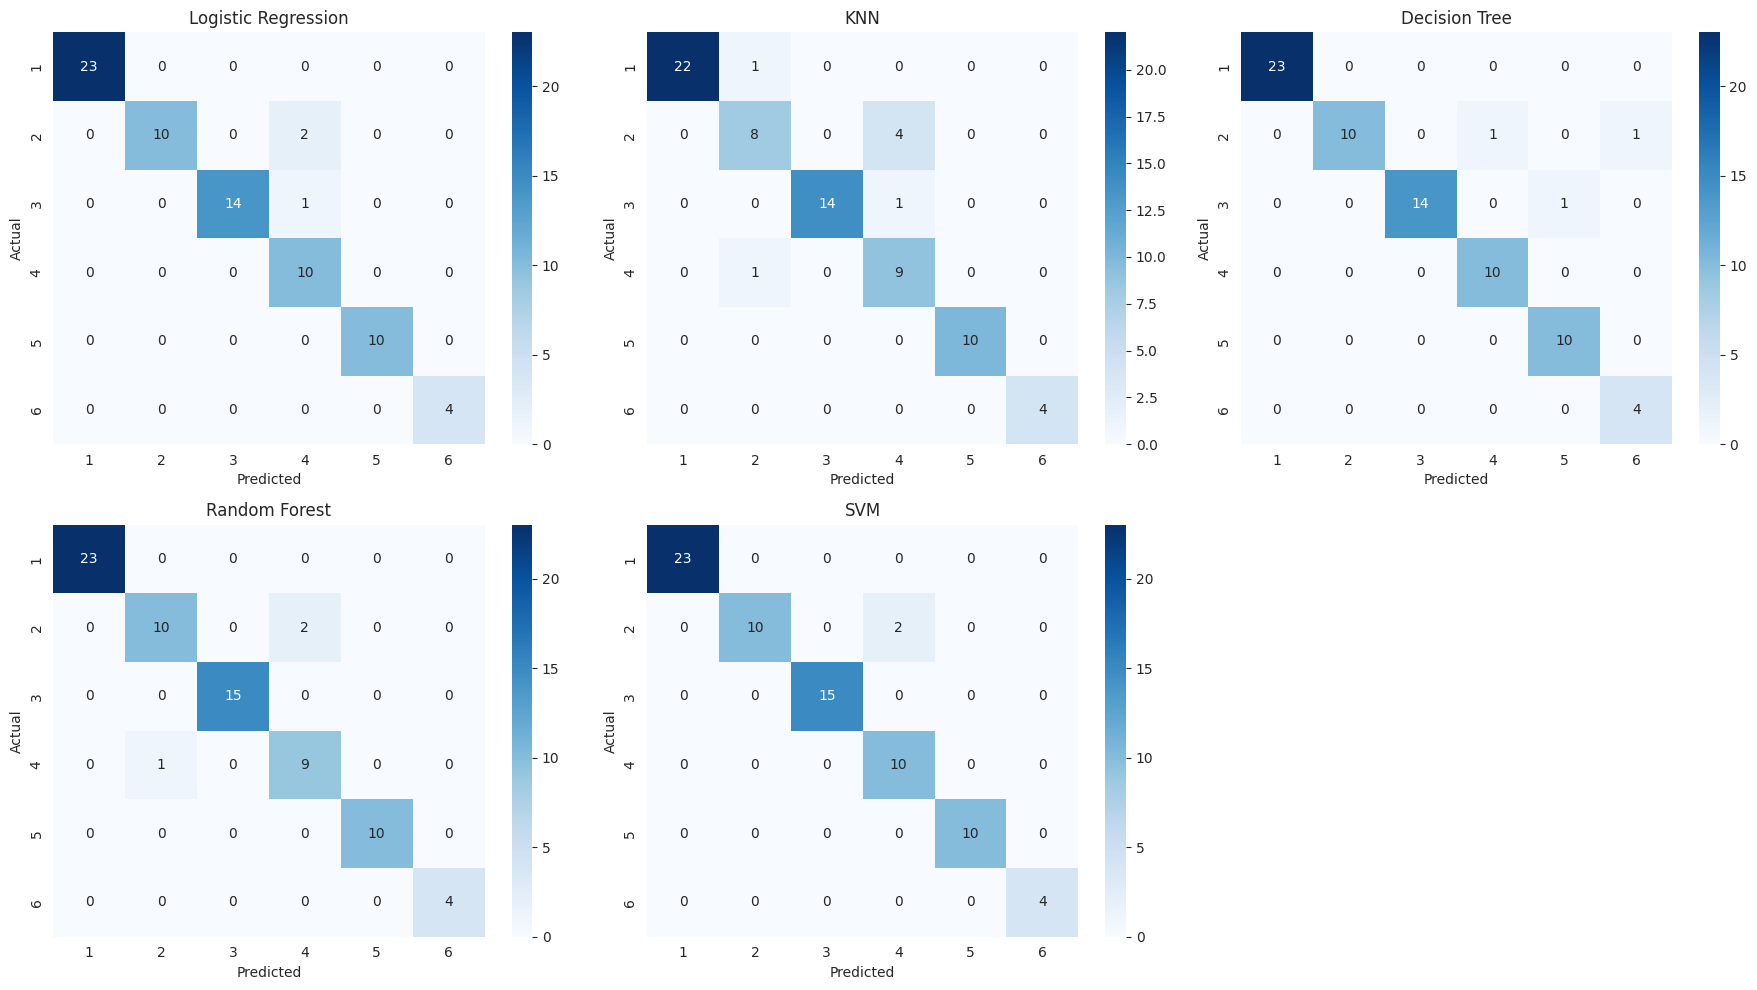

In [23]:
# Plotting the confusion matrix for every model
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[i])
    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

# hiding the unused 6th subplot
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()


### 3.3 ROC Curve and AUC score

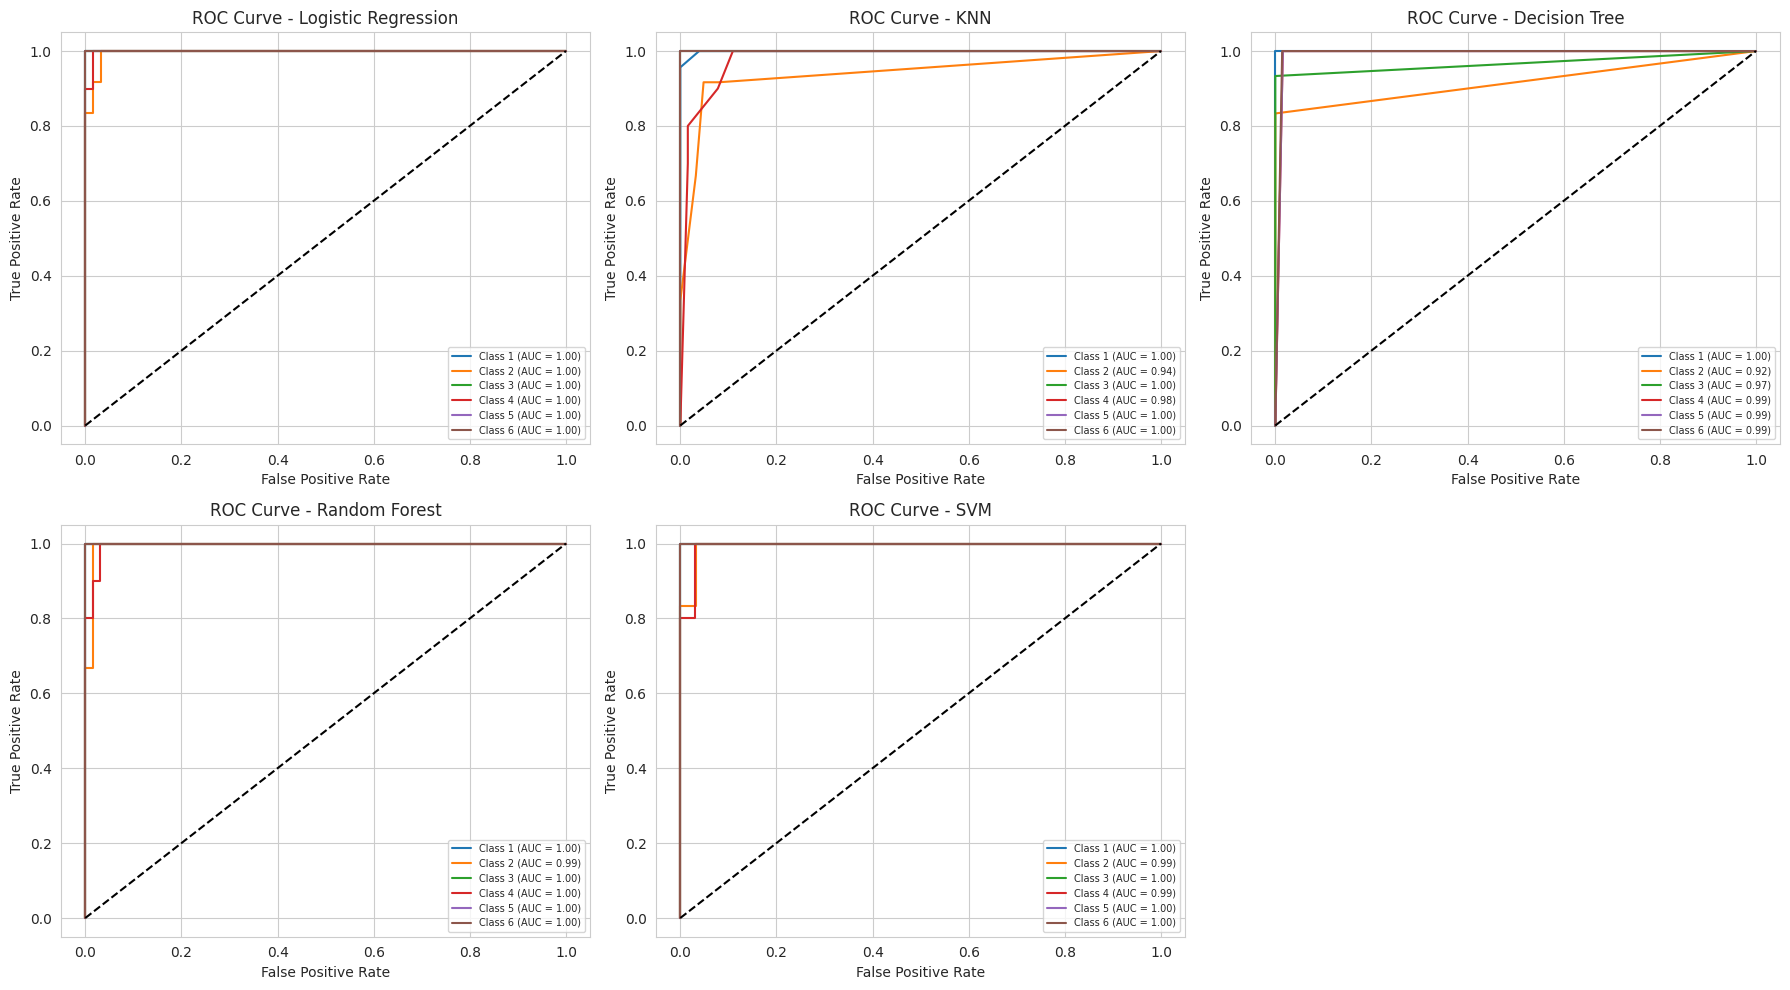

In [24]:
# ROC curves are naturally defined for binary classification, so for our 6-class problem
# we use the One-vs-Rest (OvR) approach: one ROC curve is plotted per class for each model.

# Binarizing the true labels for OvR
classes = le.classes_
n_classes = len(classes)
y_test_bin = label_binarize(y_test, classes=range(n_classes))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

auc_scores = {}

for i, (name, model) in enumerate(trained_models.items()):
    y_score = model.predict_proba(X_test_scaled)

    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    for c in range(n_classes):
        fpr[c], tpr[c], _ = roc_curve(y_test_bin[:, c], y_score[:, c])
        roc_auc[c] = auc(fpr[c], tpr[c])

    auc_scores[name] = np.mean(list(roc_auc.values()))

    for c in range(n_classes):
        axes[i].plot(fpr[c], tpr[c], label=f"Class {classes[c]} (AUC = {roc_auc[c]:.2f})")

    axes[i].plot([0, 1], [0, 1], "k--")
    axes[i].set_title(f"ROC Curve - {name}")
    axes[i].set_xlabel("False Positive Rate")
    axes[i].set_ylabel("True Positive Rate")
    axes[i].legend(fontsize=7)

fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()


In [25]:
# Average (macro) AUC score for each model, for easy comparison
auc_df = pd.DataFrame(list(auc_scores.items()), columns=["Model", "Average AUC"])
auc_df = auc_df.sort_values(by="Average AUC", ascending=False).reset_index(drop=True)
auc_df


,Model,Average AUC
0,Logistic Regression,0.999068
1,Random Forest,0.998323
2,SVM,0.998062
3,KNN,0.986262
4,Decision Tree,0.976761


### 3.4 Interpretation of results

- All five models perform quite well on this dataset (accuracy above 90% for most models),
  which shows that the clinical and histopathological features are strongly predictive of the
  disease class.
- **SVM and Logistic Regression** gave the highest accuracy and F1-scores among the models tried,
  suggesting that the classes are largely linearly/well separable after scaling the features.
- **KNN** performed slightly worse than the other models, possibly because it is more sensitive
  to the high number of features (34) and the imbalanced classes.
- Looking at the per-class precision/recall in the classification reports, the minority class
  (class 6 - pityriasis rubra pilaris) generally has lower/more variable precision and recall than
  the majority classes, which confirms the class imbalance concern raised in Task 1.
- The confusion matrices show that most misclassifications happen between classes that share
  overlapping symptoms (e.g., class 1 and class 3), which matches the real-world difficulty of
  differential diagnosis mentioned in the dataset description.
- The ROC-AUC scores are close to 1.0 for almost every class in every model, indicating that the
  models are very good at ranking/distinguishing each disease class from the rest, even though the
  dataset is small and imbalanced.

**Overall conclusion:** For this dataset, SVM (with an RBF kernel) and Logistic Regression are the
best-performing models, but Random Forest and Decision Tree are also very close and offer better
interpretability of feature importance if that is required.
